In [1]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging
logging.getLogger('harmonypy').setLevel(logging.ERROR)
logging.getLogger('harmonypy').propagate=False
logging.getLogger('harmonypy').disabled=True

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
# load manifold; report module gene recovery
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('cells:', adata.shape[0])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 1379
Gast: 77/81 genes present
pSom: 90/98 genes present
Crest: 102/104 genes present


In [4]:
# Gate 2: module geography. Low-pSom melanoma -> Crest-dominant terminal readout.
print('raw module means (LOW pSom; Crest-dominant melanoma):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
for m,lab_ in [('Gast_sm','Gastrulation'),('pSom_sm','Somitogenesis'),('Crest_sm','Neural-crest')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
# inverse-gradient vs co-expression-hub test (Gast/pSom overlap? Crest inverse?)
def enrich(x,y):
    xz=(adata.obs[x]-adata.obs[x].mean())/adata.obs[x].std()
    yz=(adata.obs[y]-adata.obs[y].mean())/adata.obs[y].std()
    joint=((xz>0.5)&(yz>0.5)).mean(); exp=(xz>0.5).mean()*(yz>0.5).mean()
    return joint/exp if exp>0 else np.nan
print(f'joint Gast&pSom-high enrichment = {enrich("Gast","pSom"):.2f} (>1 = overlap, not competing arms)')
print(f'joint pSom&Crest-high enrichment = {enrich("pSom","Crest"):.2f} (<1 = inverse gradient, not a hub)')
print(f'joint Gast&Crest-high enrichment = {enrich("Gast","Crest"):.2f}')
print('GATE 2 = GO (non-branching): Gast/pSom overlap at the origin, Crest an inverse terminal gradient;')
print('  Crest peaks at the terminus (not a Gast arm) -> no inversion flag. GATE 3 = NA (no bifurcation).')

raw module means (LOW pSom; Crest-dominant melanoma): {'Gast': -0.4919, 'pSom': -0.1392, 'Crest': 0.2006}
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.93
  Crest_sm vs Gast_sm: r = -0.91
  Crest_sm vs pSom_sm: r = -0.82
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.980
  pSom_sm: rho = -0.923
  Crest_sm: rho = +0.931
Gastrulation-high decile mean pseudotime = 0.00
Somitogenesis-high decile mean pseudotime = 0.00
Neural-crest-high decile mean pseudotime = 0.97
joint Gast&pSom-high enrichment = 1.44 (>1 = overlap, not competing arms)
joint pSom&Crest-high enrichment = 0.28 (<1 = inverse gradient, not a hub)
joint Gast&Crest-high enrichment = 0.28
GATE 2 = GO (non-branching): Gast/pSom overlap at the origin, Crest an inverse terminal gradient;
  Crest peaks at the terminus (not a Gast arm) -> no inversion flag. GATE 3 = NA (no bifurcation).


saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


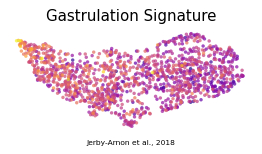

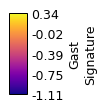

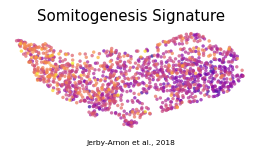

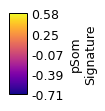

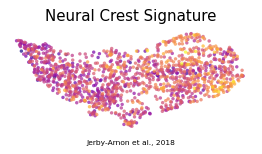

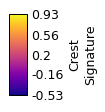

In [5]:
# signature UMAPs on the house linear layout + external colorbars (reference style)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Jerby-Arnon et al., 2018', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show()
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (1379, 21090)
